In [ ]:
# Install required libraries once
!pip install -q ultralytics==8.0.222 matplotlib opencv-python-headless tqdm torchvision


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 654.0/654.0 kB 23.2 MB/s eta 0:00:00


In [ ]:
import os
DRIVE_DATASET_PATH = "/content/drive/MyDrive/Major Project/Major/injured animal.v1.multiclass"
print("Using dataset path:", DRIVE_DATASET_PATH)
assert os.path.exists(DRIVE_DATASET_PATH), "Path not found — change DRIVE_DATASET_PATH to the correct folder."

print("Top-level:", os.listdir(DRIVE_DATASET_PATH))


Using dataset path: /content/drive/MyDrive/Major Project/Major/injured animal.v1.multiclass
Top-level: ['README.roboflow.txt', 'README.dataset.txt', 'valid', 'train', 'test']


In [ ]:
LOCAL_RAW = "dataset_raw"
if os.path.exists(LOCAL_RAW):
    !rm -rf dataset_raw
os.symlink(DRIVE_DATASET_PATH, LOCAL_RAW)
print("Symlink created:", LOCAL_RAW, "->", DRIVE_DATASET_PATH)
print("Subfolders:", os.listdir(LOCAL_RAW))


Symlink created: dataset_raw -> /content/drive/MyDrive/Major Project/Major/injured animal.v1.multiclass
Subfolders: ['README.roboflow.txt', 'README.dataset.txt', 'valid', 'train', 'test']


In [ ]:
import os, shutil, glob

INJURED_DIR = "injured_images"
os.makedirs(INJURED_DIR, exist_ok=True)

img_exts = (".jpg", ".jpeg", ".png", ".bmp")

total = 0

for split in ["train", "valid", "test"]:
    folder = os.path.join(LOCAL_RAW, split)
    files = glob.glob(folder + "/*")
    for f in files:
        if f.lower().endswith(img_exts):
            dst = os.path.join(INJURED_DIR, os.path.basename(f))
            shutil.copy2(f, dst)
            total += 1

print("Total injured images collected:", total)


Total injured images collected: 102


# **Phase 2**

In [ ]:
# Imports & config
import os, glob, random, shutil
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from tqdm import tqdm


INJURED_DIR = "injured_images"
IMG_SIZE = 224
BATCH = 16
VAL_RATIO = 0.15
EPOCHS = 20
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)
print("Looking for images in:", INJURED_DIR)


Device: cuda
Looking for images in: injured_images


In [ ]:
# Dataset class and dataloaders
class InjuredDataset(Dataset):
    def __init__(self, files, transform=None):
        self.files = files
        self.transform = transform
    def __len__(self):
        return len(self.files)
    def __getitem__(self, idx):
        p = self.files[idx]
        img = Image.open(p).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, p

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

all_files = sorted(glob.glob(os.path.join(INJURED_DIR, "*")))
random.seed(42); random.shuffle(all_files)
n = len(all_files)
n_val = max(1, int(n * VAL_RATIO))
train_files = all_files[:-n_val]
val_files = all_files[-n_val:]

print("Total images:", n, "Train:", len(train_files), "Val:", len(val_files))

train_ds = InjuredDataset(train_files, transform=transform)
val_ds   = InjuredDataset(val_files, transform=transform)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)


Total images: 102 Train: 87 Val: 15


In [ ]:
# Define Autoencoder
class AE(nn.Module):
    def __init__(self):
        super().__init__()
        res = models.resnet18(pretrained=True)
        modules = list(res.children())[:-2]   # up to last conv layer
        self.encoder_conv = nn.Sequential(*modules)  # output (B,512,7,7) for 224
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512,256,3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256,128,3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128,64,3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64,32,3,stride=2,padding=1,output_padding=1),
            nn.BatchNorm2d(32), nn.ReLU(True),
            nn.Conv2d(32,3,3,padding=1),
            nn.Sigmoid()
        )
    def forward(self,x):
        f = self.encoder_conv(x)
        out = self.decoder(f)
        if out.shape[2:] != x.shape[2:]:
            out = F.interpolate(out, size=x.shape[2:], mode='bilinear', align_corners=False)
        return out

model = AE().to(DEVICE)
print("Model params:", sum(p.numel() for p in model.parameters()))


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]


Model params: 12745539


In [ ]:
# Training loop
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

best_val = 1e9
history = {"train_loss":[], "val_loss":[]}

for epoch in range(1, EPOCHS+1):
    model.train()
    train_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [train]")
    for imgs, _ in pbar:
        imgs = imgs.to(DEVICE)
        optimizer.zero_grad()
        recon = model(imgs)
        loss = criterion(recon, imgs)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        pbar.set_postfix({"loss": f"{loss.item():.6f}"})
    train_loss = train_loss / len(train_loader.dataset)

    # validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            imgs = imgs.to(DEVICE)
            recon = model(imgs)
            loss = criterion(recon, imgs)
            val_loss += loss.item() * imgs.size(0)
    val_loss = val_loss / len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch} summary -> train_loss: {train_loss:.6f}, val_loss: {val_loss:.6f}")

    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "best_autoencoder.pth")
        print("Saved best_autoencoder.pth")


Epoch 1/20 [train]: 100%|██████████| 6/6 [00:02<00:00,  2.31it/s, loss=0.078064]


Epoch 1 summary -> train_loss: 0.074239, val_loss: 0.081323
Saved best_autoencoder.pth


Epoch 2/20 [train]: 100%|██████████| 6/6 [00:00<00:00,  7.62it/s, loss=0.070018]


Epoch 2 summary -> train_loss: 0.068195, val_loss: 0.080841
Saved best_autoencoder.pth


Epoch 3/20 [train]: 100%|██████████| 6/6 [00:00<00:00,  7.57it/s, loss=0.077786]


...

Epoch 18 summary -> train_loss: 0.016421, val_loss: 0.031574
Saved best_autoencoder.pth


Epoch 19/20 [train]: 100%|██████████| 6/6 [00:01<00:00,  5.85it/s, loss=0.014554]


Epoch 19 summary -> train_loss: 0.015559, val_loss: 0.032894


Epoch 20/20 [train]: 100%|██████████| 6/6 [00:00<00:00,  7.80it/s, loss=0.018416]


Epoch 20 summary -> train_loss: 0.015098, val_loss: 0.030892
Saved best_autoencoder.pth


In [ ]:
mse_list = []
with torch.no_grad():
    for imgs, _ in val_loader:
        imgs = imgs.to(DEVICE)
        recon = model(imgs)
        a = imgs.cpu().permute(0,2,3,1).numpy()*255
        b = recon.cpu().permute(0,2,3,1).numpy()*255
        for ai, bi in zip(a, b):
            mse_list.append(np.mean((ai - bi)**2))

mse_arr = np.array(mse_list)
mean_mse = mse_arr.mean()
std_mse = mse_arr.std()
threshold = mean_mse + 3*std_mse

print("mean_mse =", mean_mse)
print("std_mse  =", std_mse)
print("threshold =", threshold)


mean_mse = 2008.7345
std_mse  = 467.0002
threshold = 3409.735


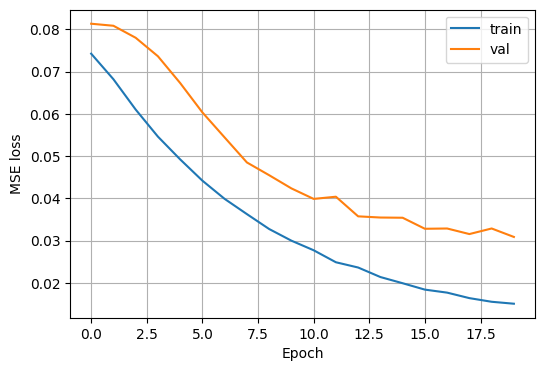

In [ ]:
# Plot loss curves
plt.figure(figsize=(6,4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("Epoch"); plt.ylabel("MSE loss"); plt.legend(); plt.grid(True)
plt.show()


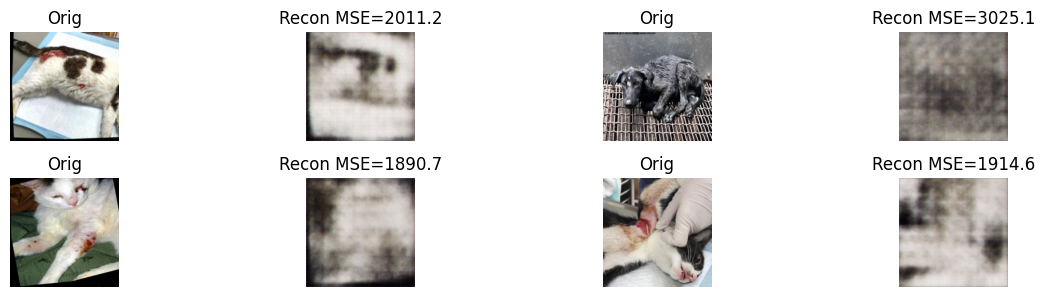

In [ ]:
# Load best model and visualize some reconstructions
model.load_state_dict(torch.load("best_autoencoder.pth", map_location=DEVICE))
model.eval()

samples = []
paths = []
with torch.no_grad():
    for imgs, ps in val_loader:
        for i in range(min(4, imgs.size(0))):
            samples.append(imgs[i].unsqueeze(0))
            paths.append(ps[i])
        if len(samples) >= 8:
            break

plt.figure(figsize=(12,6))
for i, s in enumerate(samples[:8]):
    s = s.to(DEVICE)
    with torch.no_grad():
        r = model(s)
    s_img = (s[0].cpu().permute(1,2,0).numpy()*255).astype(np.uint8)
    r_img = (r[0].cpu().permute(1,2,0).numpy()*255).astype(np.uint8)
    mse = np.mean((s_img.astype(float)-r_img.astype(float))**2)
    plt.subplot(4,4,2*i+1); plt.imshow(s_img); plt.title("Orig"); plt.axis('off')
    plt.subplot(4,4,2*i+2); plt.imshow(r_img); plt.title(f"Recon MSE={mse:.1f}"); plt.axis('off')
plt.tight_layout(); plt.show()


In [ ]:
# Compute reconstruction MSE per validation image
mse_list = []
val_paths = []
with torch.no_grad():
    for imgs, ps in val_loader:
        imgs = imgs.to(DEVICE)
        recon = model(imgs)
        a = imgs.cpu().permute(0,2,3,1).numpy()*255
        b = recon.cpu().permute(0,2,3,1).numpy()*255
        for ai, bi, p in zip(a,b,ps):
            mse_list.append(np.mean((ai - bi)**2))
            val_paths.append(p)

mse_arr = np.array(mse_list)
mean_mse = mse_arr.mean(); std_mse = mse_arr.std()
threshold = mean_mse + 3*std_mse   # simple rule
print("val mean MSE:", mean_mse, "std:", std_mse, "threshold:", threshold)


val mean MSE: 2008.7343 std: 467.0002 threshold: 3409.7349


In [ ]:
# Utility to predict MSE for a single image and decide anomaly (not_injured)
from PIL import Image

def predict_image(path, model, transform, device, threshold):
    model.eval()
    img = Image.open(path).convert("RGB")
    x = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        recon = model(x)
    a = x.cpu().permute(0,2,3,1).numpy()[0]*255
    b = recon.cpu().permute(0,2,3,1).numpy()[0]*255
    mse = float(((a - b)**2).mean())
    is_outlier = mse > threshold
    return {"path": path, "mse": mse, "is_outlier": is_outlier}

# Example usage on a few val images
for p in val_files[:5]:
    res = predict_image(p, model, transform, DEVICE, threshold)
    print(res)


{'path': 'injured_images/-2_jpg.rf.65555b03009f1b11ff5ffca4ab7a3ec0.jpg', 'mse': 2015.3992919921875, 'is_outlier': np.False_}
{'path': 'injured_images/358735_png.rf.a811f3b4dca93010cb21a5b1395b4872.jpg', 'mse': 3033.802001953125, 'is_outlier': np.False_}
{'path': 'injured_images/cat-4-_png.rf.3f3c7d34e1edc27110a90d4826aef9ec.jpg', 'mse': 1897.2430419921875, 'is_outlier': np.False_}
{'path': 'injured_images/-3_jpg.rf.4584e0a723ef7469dccd31660aff59aa.jpg', 'mse': 1923.866455078125, 'is_outlier': np.False_}
{'path': 'injured_images/cat-1-_png.rf.1442f7c143215b4fc7bb6ed308f5b37d.jpg', 'mse': 1739.418212890625, 'is_outlier': np.False_}


In [ ]:
# Colab cell
!ls -la injured_images | head
!ls -la | grep best_autoencoder.pth   # dekhega agar model current folder me saved hai
!ls -la /content/drive/MyDrive/injured_model_artifacts  # agar aapne Drive me save kiya


total 6812
drwxr-xr-x 2 root root  12288 Apr 21 09:41 .
drwxr-xr-x 1 root root   4096 Apr 21 09:42 ..
-rw------- 1 root root  38808 May 23  2025 01_379_jpg.rf.d5c0270bfbfdf8ebc7bf554bfb98a7fa.jpg
-rw------- 1 root root  78979 May 23  2025 0-1-_jpg.rf.cb67498b36799aebd681535bbd962522.jpg
-rw------- 1 root root  32343 May 23  2025 0282eae46f6d473ab1ef481ca4148105_jpg.rf.2858e55cb68841d2acc906025c6eb9a2.jpg
-rw------- 1 root root  70838 May 23  2025 0_jpg.rf.36db8ce69810bfdc64219d31794ea718.jpg
-rw------- 1 root root  77548 May 23  2025 0_jpg.rf.abc2cf7453654a6569e606f9ed20669c.jpg
-rw------- 1 root root  80029 May 23  2025 0_jpg.rf.d3152894cf234a2f72ac79be22c2303e.jpg
-rw------- 1 root root 113605 May 23  2025 1-1617837_jpg.rf.53e1865000231b909c4df37ca4a00852.jpg
-rw-r--r-- 1 root root 51077199 Apr 21 09:43 best_autoencoder.pth
total 49881
-rw------- 1 root root 51077199 Apr 15 21:00 best_autoencoder.pth


# Phase 3

In [ ]:
import json
import numpy as np

# threshold is already computed above (you can see mse values like 2015, 3033, 1897...)
# just reuse the threshold variable already in memory
with open("threshold.json", "w") as f:
    json.dump({"threshold": float(threshold)}, f)

print("Threshold saved:", threshold)

Threshold saved: 3409.7349


In [ ]:
!cp best_autoencoder.pth /content/drive/MyDrive/injured_model_artifacts/
!cp threshold.json /content/drive/MyDrive/injured_model_artifacts/
print("Both files saved to Drive!")

Both files saved to Drive!
